In [10]:
import pandas as pd
import numpy as np


In [11]:
df=pd.read_csv(r"C:\Users\HP\OneDrive\Desktop\Datascience_internship\dataset\Dataset .csv")

In [5]:
import webbrowser



In [7]:
import folium

m = folium.Map(
    location=[df['Latitude'].mean(), df['Longitude'].mean()],
    zoom_start=2
)

for _, row in df.dropna(subset=['Latitude', 'Longitude']).iterrows():
    folium.CircleMarker(
        location=[row['Latitude'], row['Longitude']],
        radius=3,
        popup=f"{row['City']} - Rating: {row['Aggregate rating']}"
    ).add_to(m)

m

In [8]:
city_count=df['City'].value_counts()

<Axes: title={'center': 'top 10 cites'}, xlabel='City'>

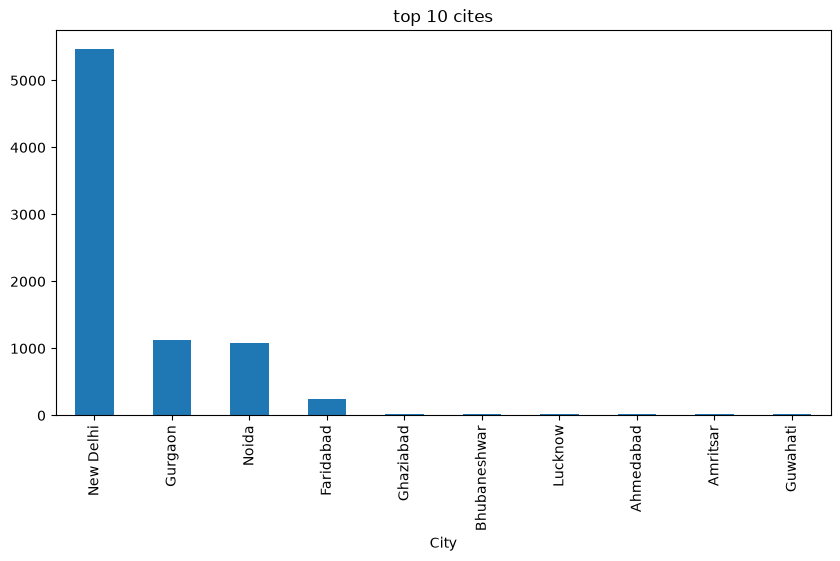

In [9]:
city_count.head(10).plot(
    kind='bar',
    figsize=(10,5),
    title='top 10 cites'
)

In [13]:
country_code=df['Country Code'].value_counts()

<Axes: title={'center': 'top ten countrys'}, xlabel='Country Code'>

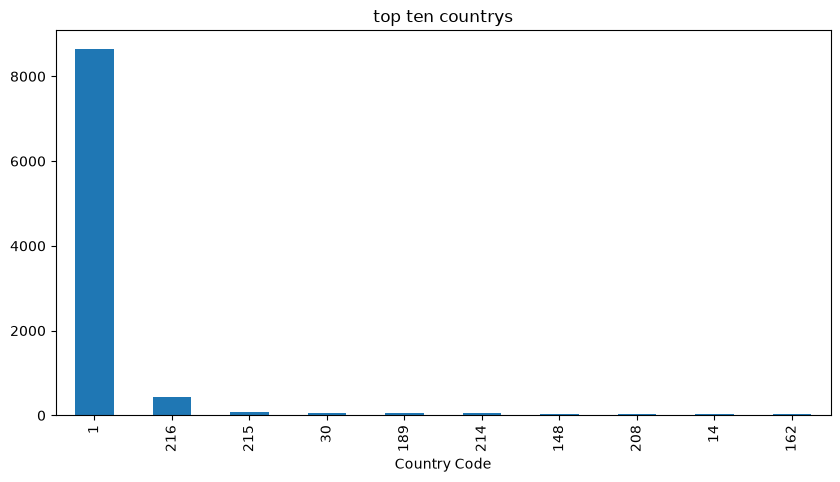

In [14]:
country_code.head(10).plot(
    kind='bar',
    figsize=(10,5),
    title='top ten countrys'
)

In [15]:
city_analysis = df.groupby('City').agg(
    restaurant_count=('Restaurant Name', 'count'),
    average_rating=('Aggregate rating', 'mean')
)

print(city_analysis.sort_values(
    'restaurant_count',
    ascending=False
).head(10))

              restaurant_count  average_rating
City                                          
New Delhi                 5473        2.438845
Gurgaon                   1118        2.651431
Noida                     1080        2.036204
Faridabad                  251        1.866932
Ghaziabad                   25        2.852000
Bhubaneshwar                21        3.980952
Lucknow                     21        4.195238
Guwahati                    21        4.190476
Ahmedabad                   21        4.161905
Amritsar                    21        3.685714


In [16]:
print(df[['Latitude', 'Longitude', 'Aggregate rating']].corr())

                  Latitude  Longitude  Aggregate rating
Latitude          1.000000   0.043207          0.000516
Longitude         0.043207   1.000000         -0.116818
Aggregate rating  0.000516  -0.116818          1.000000
